<center><h1>Guo_Haosen_HW5</h1></center>
<br>
<br>

Name: Haosen Guo
<br>
Github Username: iamevan-g
<br>
USC ID: 7183115772

## 1. Decision Trees as Interpretable Models

Import packages

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, cross_val_score

### (a) Obtain Data

Get the Accute Inamations Data Set

In [29]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains",
        "burning_urethra", "bladder_inflammation", "nephritis"]
# File is UTF-16 encoded with comma decimals
df = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, names=cols,
                 encoding="utf-16", decimal=",")
df[cols[1:]] = (df[cols[1:]] == "yes").astype(int)

X = df[cols[:6]]
# Label powerset: combine two labels into one class
y = df["bladder_inflammation"].astype(str) + df["nephritis"].astype(str)
y.value_counts()

10    40
01    31
00    30
11    19
Name: count, dtype: int64

### (b) Build a decision tree

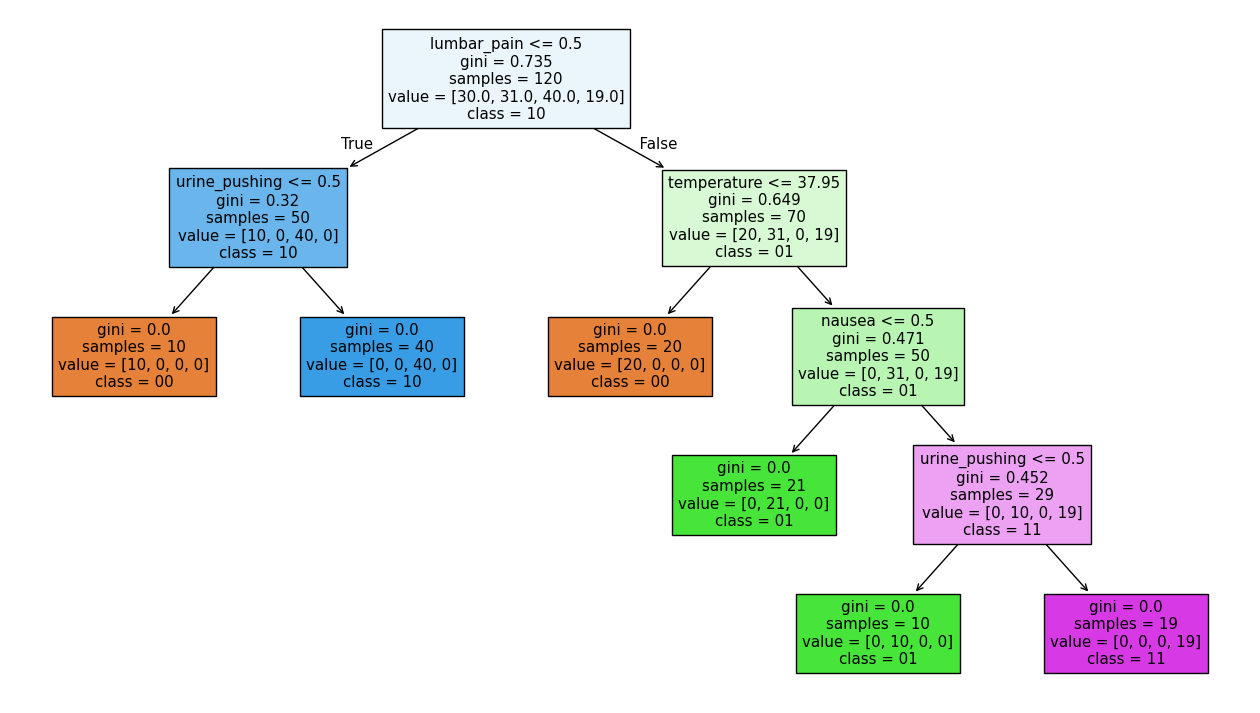

In [30]:
clf = DecisionTreeClassifier(random_state=42).fit(X, y)

plt.figure(figsize=(16, 9))
plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True)
plt.show()

### (c) Convert the decision rules

In [31]:
def tree_to_rules(model, features):
    t = model.tree_
    rules = []
    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = features[t.feature[node]], t.threshold[node]
            recurse(t.children_left[node], conds + [f"{name} <= {thr:.2f}"])
            recurse(t.children_right[node], conds + [f"{name} > {thr:.2f}"])
        else:
            label = model.classes_[np.argmax(t.value[node])]
            rules.append(f"IF {' AND '.join(conds)} THEN {label}")
    recurse(0, [])
    return rules

print("\n".join(tree_to_rules(clf, X.columns)))

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 00
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 10
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN 00
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 11


###  (d) cost-complexity pruning

      alpha    cv_acc
0  0.000000  0.991667
1  0.098167  0.858333
2  0.133333  0.758333
3  0.182000  0.666667
4  0.222917  0.483333


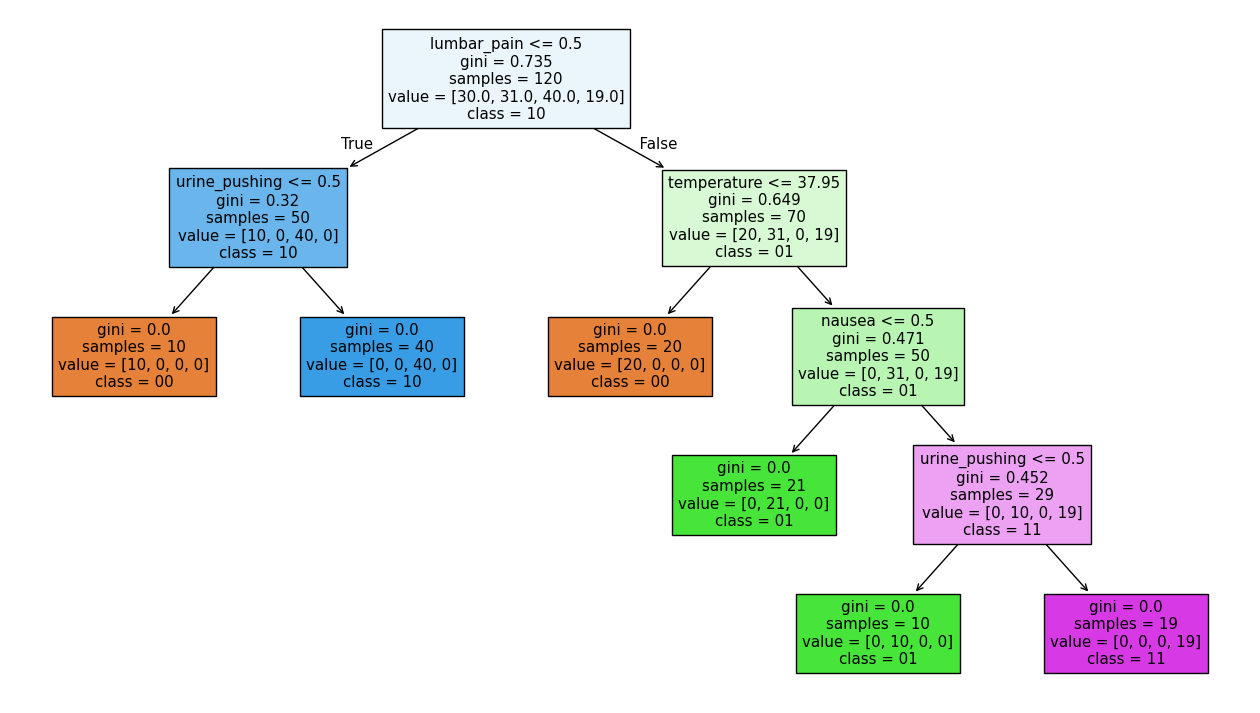

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN 00
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN 10
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN 00
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN 01
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN 11


In [32]:
alphas = clf.cost_complexity_pruning_path(X, y).ccp_alphas
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = [cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a),
                          X, y, cv=cv).mean() for a in alphas]
print(pd.DataFrame({"alpha": alphas, "cv_acc": scores}))

# Largest alpha among the best CV scores -> smallest tree
best_alpha = alphas[np.flatnonzero(scores == np.max(scores))[-1]]
pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X, y)

plt.figure(figsize=(16, 9))
plot_tree(pruned, feature_names=X.columns, class_names=pruned.classes_, filled=True)
plt.show()
print("\n".join(tree_to_rules(pruned, X.columns)))

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [33]:
from sklearn.impute import SimpleImputer

# Column names come from @attribute lines in the .names file
with open("../data/communities.names") as f:
    names = [line.split()[1] for line in f if line.startswith("@attribute")]
df = pd.read_csv("../data/communities.data", header=None, names=names, na_values="?")
df.shape

(1994, 128)

### (b) Missing values

In [34]:
# Drop non-predictive features
df = df.drop(columns=["state", "county", "community", "communityname", "fold"])
missing = df.isna().sum()
print(missing[missing > 0])

train, test = df.iloc[:1495], df.iloc[1495:]

# Fit imputer on training set only to avoid leakage
imputer = SimpleImputer(strategy="median").fit(train)
train = pd.DataFrame(imputer.transform(train), columns=df.columns)
test = pd.DataFrame(imputer.transform(test), columns=df.columns)

target = "ViolentCrimesPerPop"
X_train, y_train = train.drop(columns=target), train[target]
X_test, y_test = test.drop(columns=target), test[target]

OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64


### (c) Plot a correlation matrix

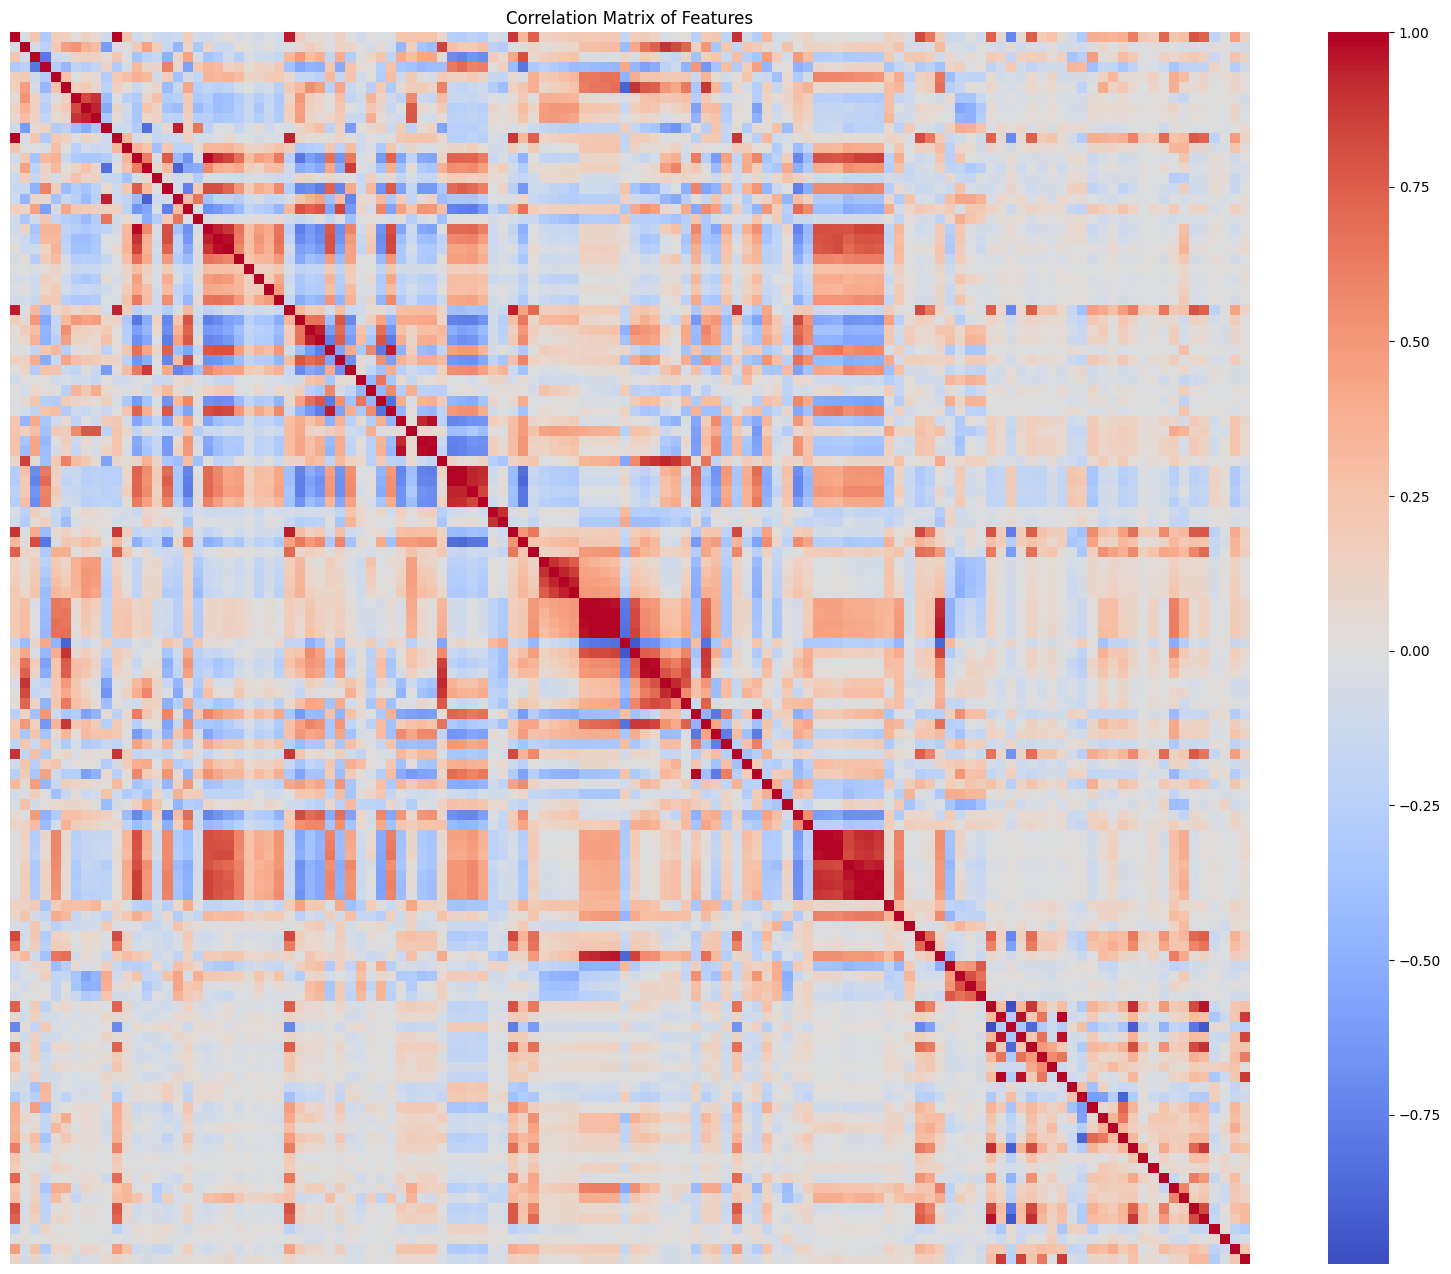

In [35]:
import seaborn as sns

X = pd.concat([X_train, X_test])
plt.figure(figsize=(20, 16))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlation Matrix of Features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [36]:
cv = (X.std() / X.mean()).sort_values(ascending=False)
cv

PctPolicAsian          5.447835
NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
                         ...   
NumKindsDrugsSeiz      0.143227
RacialMatchCommPol     0.126902
LemasPctPolicOnPatr    0.117807
PctPolicWhite          0.117726
LemasSwFTFieldOps      0.057515
Length: 122, dtype: float64

### (e) Scatter plots and box plots for highest CV features

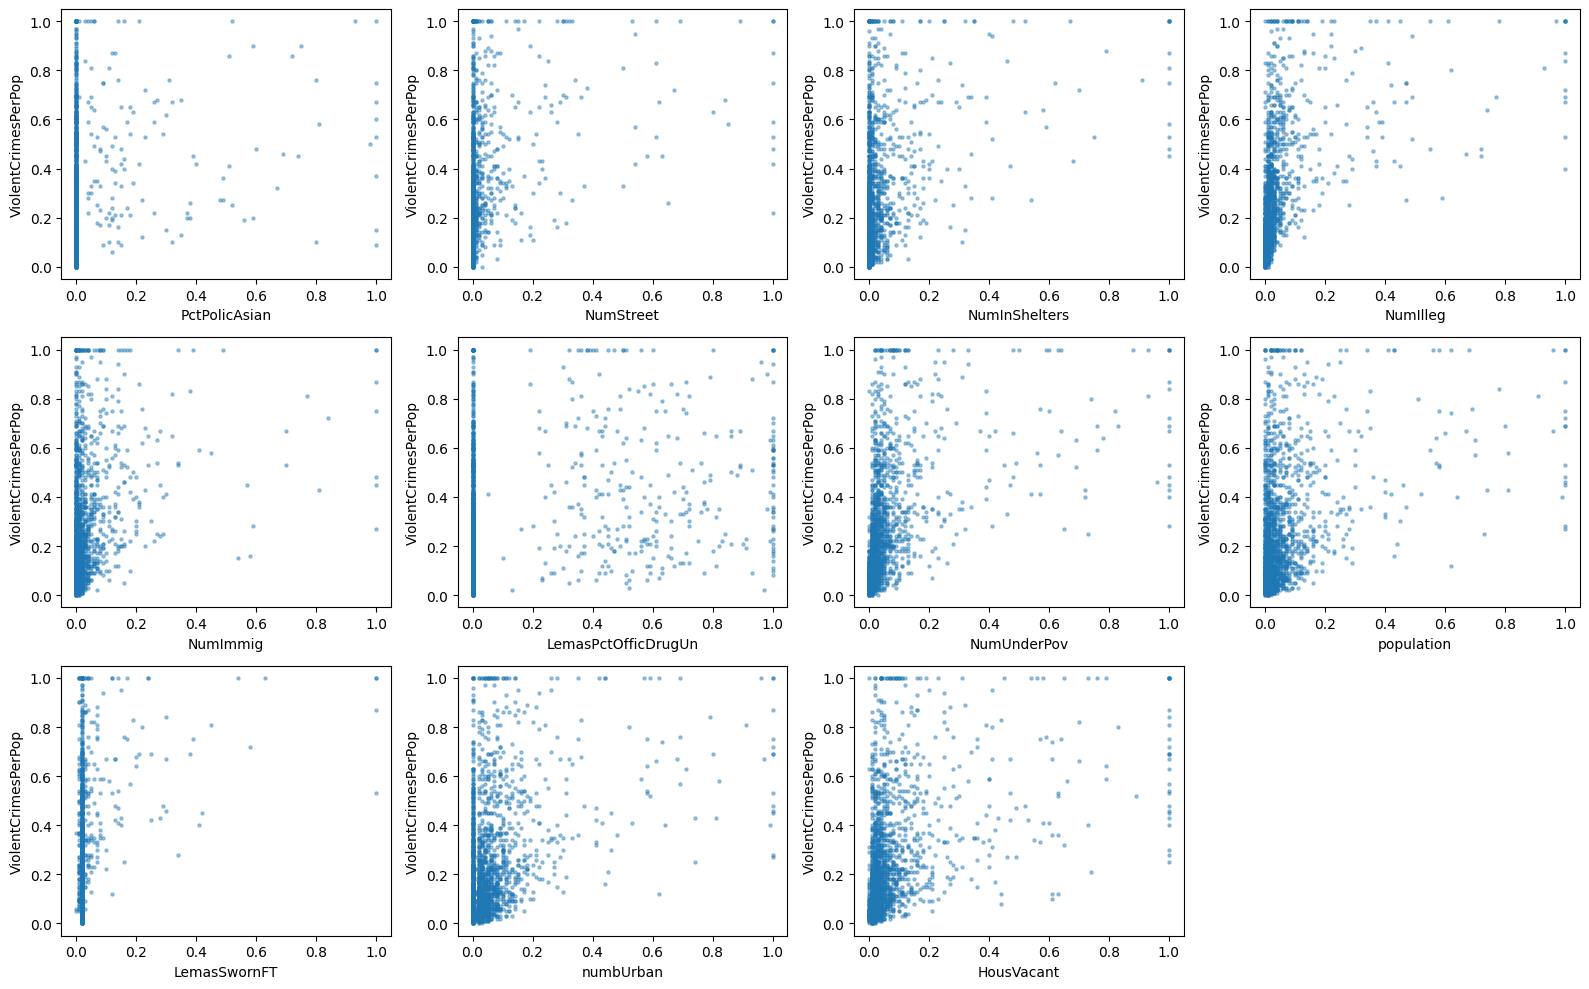

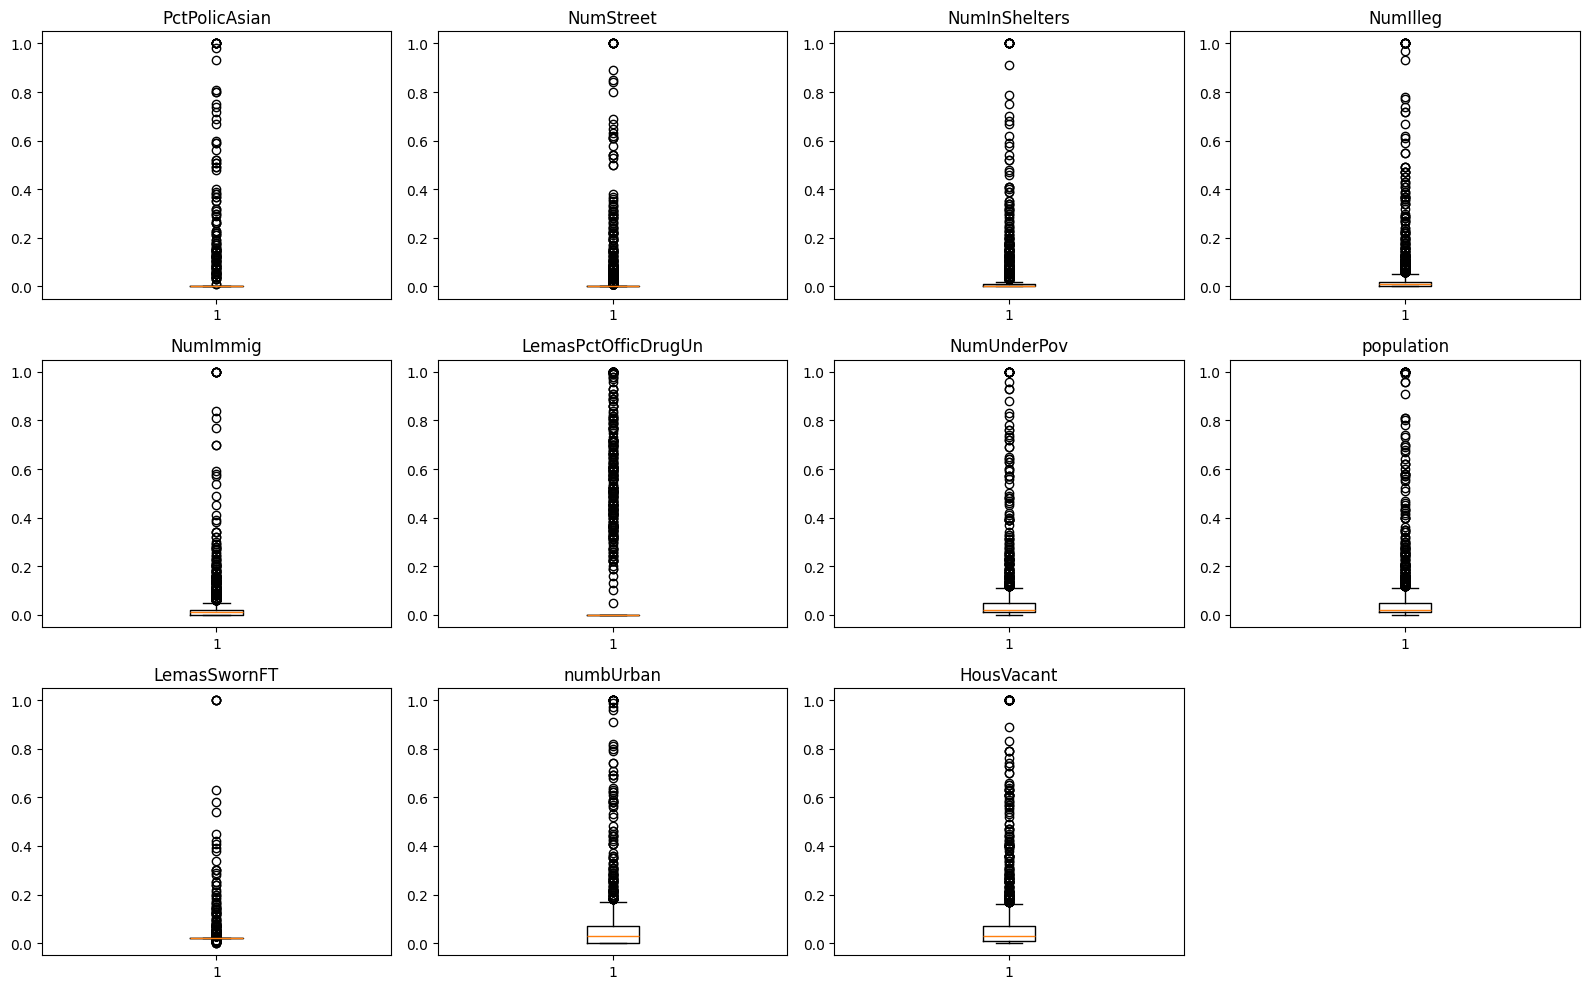

In [37]:
y = pd.concat([y_train, y_test])
top = cv.index[:int(np.sqrt(128))]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, top):
    ax.scatter(X[col], y, s=5, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, top):
    ax.boxplot(X[col])
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

No. The scatter plots show that most values are concentrated near 0 with a few extreme points, and no clear linear trend with ViolentCrimesPerPop is visible. Scatter plots only show marginal relationships; significance should be assessed by a fitted model, since it depends on the other features as well.

### (f) Fit a linear model

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# PolicPerPop is identical to LemasSwFTPerPop in the training set (perfect collinearity)
X_train_ols = X_train.drop(columns="PolicPerPop")
X_test_ols = X_test.drop(columns="PolicPerPop")

ols = LinearRegression().fit(X_train_ols, y_train)
print("Test MSE:", mean_squared_error(y_test, ols.predict(X_test_ols)))

Test MSE: 0.01796607862869666


### (g) Fit a ridge regression model

In [39]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

kf = KFold(n_splits=10, shuffle=True, random_state=42)
ridge = RidgeCV(alphas=np.logspace(-4, 4, 100), cv=kf).fit(X_train, y_train)
print("Best lambda:", ridge.alpha_)
print("Test MSE:", mean_squared_error(y_test, ridge.predict(X_test)))

Best lambda: 3.351602650938848
Test MSE: 0.017472388425329194


### (h) Fit a LASSO model

In [40]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Original (already normalized) features
lasso = LassoCV(cv=kf, max_iter=50000, random_state=42).fit(X_train, y_train)
selected = X_train.columns[lasso.coef_ != 0]
print("Best lambda:", lasso.alpha_)
print("Test MSE:", mean_squared_error(y_test, lasso.predict(X_test)))
print(f"{len(selected)} variables selected:\n", list(selected))

# Standardized features
lasso_std = make_pipeline(StandardScaler(), LassoCV(cv=kf, max_iter=50000, random_state=42))
lasso_std.fit(X_train, y_train)
selected_std = X_train.columns[lasso_std[-1].coef_ != 0]
print("Best lambda:", lasso_std[-1].alpha_)
print("Test MSE:", mean_squared_error(y_test, lasso_std.predict(X_test)))
print(f"{len(selected_std)} variables selected:\n", list(selected_std))

Best lambda: 0.00012454087437758504
Test MSE: 0.017617760569778634
74 variables selected:
 ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelte

### (i) Fit a PCR model

In [41]:
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV

pcr = make_pipeline(StandardScaler(), PCA(), LinearRegression())
grid = GridSearchCV(pcr, {"pca__n_components": range(1, X_train.shape[1] + 1)},
                    cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
print("Best M:", grid.best_params_["pca__n_components"])
print("Test MSE:", mean_squared_error(y_test, grid.predict(X_test)))

Best M: 95
Test MSE: 0.018296345367709813


### (j) Fit a boosting tree

In [42]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
# reg_alpha is the L1 regularization term
grid = GridSearchCV(xgb, {"reg_alpha": np.logspace(-4, 1, 11)}, cv=kf,
                    scoring="neg_mean_squared_error").fit(X_train, y_train)
print("Best alpha:", grid.best_params_["reg_alpha"])
print("Test MSE:", mean_squared_error(y_test, grid.predict(X_test)))

Best alpha: 0.31622776601683794
Test MSE: 0.01625790082430119
